# Norton & Scharff (2016) data

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd

import sys
sys.path.append('../')
from src.rhythm_types import aggregate_units
from src.data import save_units
from src.viz.utils import set_mpl_style, subplot_title, ylabel_annot
set_mpl_style()

# Load data location from .env file
from dotenv import load_dotenv
load_dotenv()
if not os.getenv("NS_DIR"):
    raise Exception("NS_DIR environment variable not set")
DATA_DIR = Path(os.getenv("NS_DIR"))

ROOT_DIR = Path('.').resolve().parent
DATASET_ID = 'ns' # Norton & Scharff
OUTPUT_DIR = ROOT_DIR / 'data'

## Preprocess original data

In [2]:
def load_csv_data(base_dir: Path | str = DATA_DIR) -> pd.DataFrame:
    """Load and concatenate cleaned CSV files from the dataset directory."""
    base_path = Path(base_dir)
    clean_dir = base_path / "clean-data"
    paths = sorted(clean_dir.glob("*.csv"))
    if not paths:
        raise FileNotFoundError(f"No CSV files found in {clean_dir}")

    dfs = [pd.read_csv(path) for path in paths]
    return pd.concat(dfs, ignore_index=True)

In [3]:
df = load_csv_data().sort_values(['bird_id', 'chunk_idx'])
df.head()

,start,end,syllable,gap_before,gap_after,bird_id,chunk_idx,syllable_idx
0,305.5891,305.6820,a,NaN,0.0435,2994,1,1
1,305.7255,305.7981,b,0.0435,0.0406,2994,1,2
2,305.8387,305.9693,c,0.0406,0.0407,2994,1,3
3,306.0100,306.1057,d,0.0407,0.0378,2994,1,4
4,306.1435,306.3409,e,0.0378,0.0406,2994,1,5


In [4]:
def iter_chunks():
    for bird_id in df['bird_id'].unique():
        bird_df = df[df['bird_id'] == bird_id]
        for chunk_idx in bird_df['chunk_idx'].unique():
            chunk_df = bird_df[bird_df['chunk_idx'] == chunk_idx]
            yield dict(
                chunk_df=chunk_df, 
                start_col='start',
                end_col='end',
                label_col='syllable',
                bird_id=f"ns-{bird_id}",
                chunk_idx=chunk_idx
            )

In [5]:
# Get the units of every rhythm type
units = aggregate_units(iter_chunks(), level='syll')

# Save
for rhythm_type, rhythm_units in units.items():
    save_units(rhythm_units, rhythm_type, DATASET_ID, OUTPUT_DIR)

Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).


Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).
Cannot extract gap IOIs from 1 gap(s).


## Augment

In [6]:
from src.constants import DATASETS
from src.data import load_units
from src.pipeline.predict_bird_ids import predict_bird_ids
from src.viz.changepoints import plot_changepoints

from src.pipeline.fit_hmms import get_output_dir
from src.hmm import load_fit
from src.metrics.permutation import shuffle_labels_within_chunk

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.



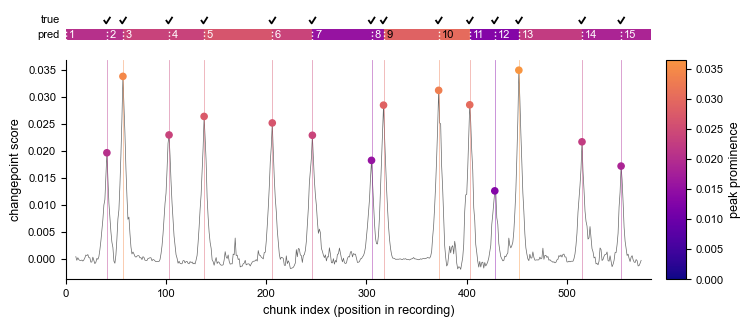

In [7]:
# Illustration predicting bird ids

units = load_units('ns', 'syll_ioi', use_milliseconds=False)
result = predict_bird_ids(units, half_window=10, min_gap=5, id_prefix='ns-pred-')
fig, ax_tl, ax = plot_changepoints(
    result,
    result['n_chunks'],
    true_breakpoints=result['true_breakpoints'],
    tolerance=5,
)
ax.set_xlabel('chunk index (position in recording)');

In [8]:
# Add bird and label predictions to all rhythm types

for rhythm_type in DATASETS[DATASET_ID]['rhythm_types']:
    # Seeded by rhythm type, so the shuffle doesn't depend on loop order
    rng = np.random.default_rng([0, *rhythm_type.encode()])

    units = load_units(DATASET_ID, rhythm_type, use_milliseconds=False)

    # Bird id predictions
    result = predict_bird_ids(units, half_window=10, min_gap=5, id_prefix='ns-pred-')
    units['bird_id_pred'] = result['bird_id_pred']

    # Label predictions
    for bird_id, bird_group in units.groupby('bird_id'):
        path = get_output_dir(DATASET_ID, rhythm_type) / f"{bird_id}.joblib"
        result = load_fit(path)
        # The fit lists the chunks in chunk order, so the units must be too.
        assert bird_group['chunk_idx'].is_monotonic_increasing
        units.loc[bird_group.index, 'label_pred'] = np.concatenate(result['labels'])

    # Shuffled baseline for plots: a single, fixed within-chunk shuffle of the
    # annotated labels. The permutation tests instead reshuffle many times
    # (collect_permutation_tests.py; see src/metrics/README.md).
    units['label_shuffle'] = shuffle_labels_within_chunk(
        units, rng, by=['bird_id', 'chunk_idx'], label_col='label',
    )['label']

    # Save new units
    save_units(units, rhythm_type, DATASET_ID, OUTPUT_DIR)

## Example

In [9]:
from src.rhythm_types import (
    get_bound_units_from_chunk,
    get_dur_units,
    get_ioi_units,
)


In [10]:
chunk_idx = 2
bird_df = df[df['bird_id'] == 2994]
chunk_df = bird_df[bird_df['chunk_idx'] == chunk_idx]
units = get_bound_units_from_chunk(
    chunk_df, 
    start_col='start', 
    end_col='end', 
    label_col='syllable', 
    bird_id='2994', 
    chunk_idx=chunk_idx
)
units

,start,duration,is_gap,label,chunk_idx,bird_id
0,310.3637,0.0958,False,a,2,2994
1,310.4595,0.0435,True,ab,2,2994
2,310.5030,0.0697,False,b,2,2994
3,310.5727,0.0406,True,bc,2,2994
4,310.6133,0.1306,False,c,2,2994
5,310.7439,0.0407,True,cd,2,2994
6,310.7846,0.0928,False,d,2,2994
7,310.8774,0.0407,True,de,2,2994
8,310.9181,0.1973,False,e,2,2994
9,311.1154,0.0436,True,ef,2,2994


In [11]:
dur_units = get_dur_units(units)
dur_units.head()

,start,duration,label,chunk_idx,bird_id
0,310.3637,0.0958,a,2,2994
1,310.5030,0.0697,b,2,2994
2,310.6133,0.1306,c,2,2994
3,310.7846,0.0928,d,2,2994
4,310.9181,0.1973,e,2,2994


In [12]:
gap_dur_units = get_dur_units(units, gaps=True)
gap_dur_units

,start,duration,label,chunk_idx,bird_id
0,310.4595,0.0435,ab,2,2994
1,310.5727,0.0406,bc,2,2994
2,310.7439,0.0407,cd,2,2994
3,310.8774,0.0407,de,2,2994
4,311.1154,0.0436,ef,2,2994
5,311.3332,0.0435,fc,2,2994
6,311.5102,0.0406,cd,2,2994
7,311.6495,0.0378,de,2,2994
8,311.8875,0.0465,ef,2,2994
9,312.1110,0.0552,fa,2,2994


In [13]:
ioi_units = get_ioi_units(units)
ioi_units.head()

,start,duration,label,chunk_idx,bird_id
0,310.3637,0.1393,ab,2,2994
1,310.5030,0.1103,bc,2,2994
2,310.6133,0.1713,cd,2,2994
3,310.7846,0.1335,de,2,2994
4,310.9181,0.2409,ef,2,2994


In [14]:
gap_ioi_units = get_ioi_units(units, gaps=True)
gap_ioi_units.head()

,start,duration,label,chunk_idx,bird_id
0,310.4595,0.1132,ab,2,2994
1,310.5727,0.1712,bc,2,2994
2,310.7439,0.1335,cd,2,2994
3,310.8774,0.2380,de,2,2994
4,311.1154,0.2178,ef,2,2994
